<a href="https://colab.research.google.com/github/kulanigayathree/J26-IT-364/blob/model%2FFishing-Zone-Prediction/notebooks/C2_fishing_zone_prediction/C2_6_compare_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# C2 – Notebook 6: Compare all models and choose the best

Reads the saved results of Notebooks 2–5 (no training here, no GPU needed).

**Selection rule:** the deep model with the highest **validation (2022) PR-AUC** is chosen.
The **test (2023–24)** scores are then reported for all models. Choosing on validation and reporting
on test keeps the test years "unseen" — this is what makes the comparison honest.

## Step 1 – Connect Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, glob, numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
BASE = '/content/drive/MyDrive/C2_data'; OUT = f'{BASE}/results'

Mounted at /content/drive


## Step 2 – Collect all results

In [2]:
val  = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f'{OUT}/*_val_scores.csv'))],  ignore_index=True)
test = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f'{OUT}/*_test_scores.csv'))], ignore_index=True)

order = ['Climatology', 'Gradient Boosting', 'U-Net (space only)', 'ConvGRU (space + time)',
         'ConvLSTM (space + time)', 'Persistence (upper ref.)']
order = [m for m in order if m in set(test.model)] + [m for m in test.model.unique() if m not in order]

table = test.pivot(index='model', columns='lead_day', values='PR_AUC').reindex(order)
table.columns = [f'PR-AUC Day {c}' for c in table.columns]
table['PR-AUC mean'] = table.mean(axis=1)
table['ROC-AUC mean'] = test.groupby('model').ROC_AUC.mean()
table['Brier mean'] = test.groupby('model').Brier.mean()
table['val PR-AUC (2022)'] = val.groupby('model').PR_AUC.mean()
print('TEST 2023-24  (higher PR-AUC / ROC-AUC = better, lower Brier = better)')
print(table.round(4).to_string())
table.round(4).to_csv(f'{OUT}/model_comparison.csv')

TEST 2023-24  (higher PR-AUC / ROC-AUC = better, lower Brier = better)
                          PR-AUC Day 1  PR-AUC Day 2  PR-AUC Day 3  PR-AUC mean  ROC-AUC mean  Brier mean  val PR-AUC (2022)
model                                                                                                                       
Climatology                     0.2307        0.2307        0.2308       0.2307        0.6272      0.1349             0.1785
Gradient Boosting               0.2286        0.2286        0.2283       0.2285        0.6319      0.1356             0.1661
U-Net (space only)              0.2728        0.2734        0.2756       0.2739        0.6672      0.1161             0.2123
ConvGRU (space + time)          0.2826        0.2835        0.2842       0.2834        0.6950      0.1158             0.2175
ConvLSTM (space + time)         0.2808        0.2814        0.2800       0.2807        0.6875      0.1161             0.2123
Persistence (upper ref.)        0.5914        0.5659  

## Step 3 – Choose the best deep-learning model (by validation PR-AUC)

In [3]:
deep = {'U-Net (space only)': 'unet', 'ConvLSTM (space + time)': 'convlstm', 'ConvGRU (space + time)': 'convgru'}
cand = table.loc[[m for m in deep if m in table.index], 'val PR-AUC (2022)']
best_label = cand.idxmax(); best_key = deep[best_label]
open(f'{OUT}/best_model.txt', 'w').write(best_key)
print('Validation PR-AUC of deep models:'); print(cand.round(4).to_string())
print(f'\nBEST MODEL: {best_label}  -> saved to results/best_model.txt (the demo uses it)')
print(f'Its test PR-AUC (2023-24): {table.loc[best_label, "PR-AUC mean"]:.4f}')
for ref in ['Climatology', 'Gradient Boosting']:
    if ref in table.index:
        diff = table.loc[best_label, 'PR-AUC mean'] - table.loc[ref, 'PR-AUC mean']
        print(f'  vs {ref}: {diff:+.4f}')

Validation PR-AUC of deep models:
model
U-Net (space only)         0.2123
ConvLSTM (space + time)    0.2123
ConvGRU (space + time)     0.2175

BEST MODEL: ConvGRU (space + time)  -> saved to results/best_model.txt (the demo uses it)
Its test PR-AUC (2023-24): 0.2834
  vs Climatology: +0.0527
  vs Gradient Boosting: +0.0549


## Step 4 – Charts for the report

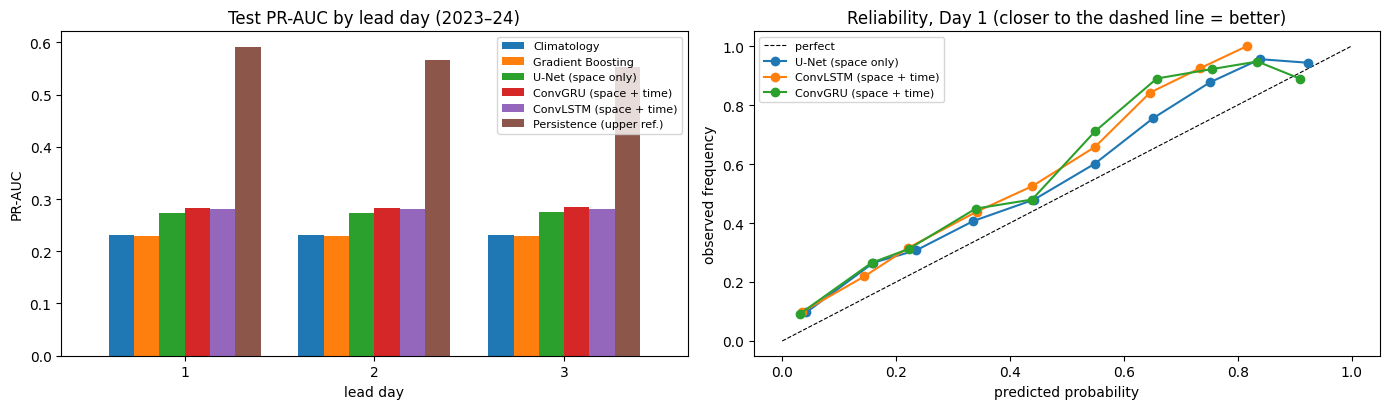

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
pr = test.pivot(index='lead_day', columns='model', values='PR_AUC')[order]
pr.plot(kind='bar', ax=ax[0], width=0.8)
ax[0].set_title('Test PR-AUC by lead day (2023–24)'); ax[0].set_xlabel('lead day'); ax[0].set_ylabel('PR-AUC')
ax[0].legend(fontsize=8); ax[0].tick_params(axis='x', rotation=0)

# reliability (Day 1) for the deep models
X = xr.open_dataset(f'{BASE}/datacube_0p25.nc')
ocean = X['depth'].isel(time=0).notnull().values
label = np.nan_to_num(X['fishing'].values)
ax[1].plot([0, 1], [0, 1], 'k--', lw=0.8, label='perfect')
for lab, key in deep.items():
    f = f'{OUT}/{key}_test_predictions.npz'
    if not os.path.exists(f): continue
    z = np.load(f); p = z['mean'][:, 0][:, ocean].astype('float32').ravel(); y = label[z['ids'] + 1][:, ocean].ravel()
    b = np.digitize(p, np.linspace(0, 1, 11)) - 1
    r = pd.DataFrame({'b': b, 'p': p, 'y': y}).groupby('b').agg(pred=('p', 'mean'), obs=('y', 'mean'))
    ax[1].plot(r.pred, r.obs, 'o-', label=lab)
ax[1].set_xlabel('predicted probability'); ax[1].set_ylabel('observed frequency')
ax[1].set_title('Reliability, Day 1 (closer to the dashed line = better)'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/model_comparison.png', dpi=130); plt.show()

### How to read this (for the report)
* **Gradient Boosting vs deep models** → does seeing neighbouring cells / past days help?
* **U-Net vs ConvLSTM/ConvGRU** → does the **time** dimension (7 past days) add skill beyond spatial patterns?
* **ConvLSTM vs ConvGRU** → does the richer memory help, or is the simpler model enough?
* **Persistence** uses live fishing data (not available to the real system) → an upper reference only.

Saved: `results/model_comparison.csv`, `results/model_comparison.png`, `results/best_model.txt`.